# 06 · Final evaluation on the test set

Every decision in this project was made on the cv set: the features, the fraud weight, the learning rate, when to stop training and the decision threshold. Making decisions on a set slowly fits them to it, so the cv numbers are slightly optimistic.

The test set (Kaggle's own test file, 21 June to 31 December 2020) has not been used for anything until now. This notebook scores it **once** with the two published bundles, each with the threshold it was released with. Nothing is tuned here, and nothing in the models changes after this point because of what it shows: these are the honest numbers.

In [1]:
from pathlib import Path

# Reload the project packages automatically, so code edits show up without restarting the kernel.
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Fixed colors: blue is always "legit", orange is always "fraud".
LEGIT, FRAUD = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[LEGIT, FRAUD, "#1baf7a", "#eda100"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

In [2]:
from fraud_core.history import card_history
from fraud_core.model import FraudModel
from fraud_training.data import ROOT, load_raw, split_by_time
from fraud_training.evaluate import cost_by_threshold, evaluate

In [3]:
df = load_raw()
df = df.join(card_history(df))  # the test period sees each card's history from cv, as it would in production
split = split_by_time(df)
test = split.test
y_test = test["is_fraud"].to_numpy()
amounts = test["amt"].to_numpy()
split.summary()

,from,to,rows,frauds,fraud_rate_%
train,2019-01-01,2019-12-31,924850,5220,0.564
cv,2020-01-01,2020-06-21,371825,2286,0.615
test,2020-06-21,2020-12-31,555719,2145,0.386


## Both models, each at its released threshold

In [4]:
models = {version: FraudModel.load(ROOT.parent / "models" / version) for version in ["1.0.0", "2.0.0"]}

rows = []
for version, model in models.items():
    prob = model.predict_proba(test)
    metrics = evaluate(y_test, prob, threshold=model.threshold)
    cost = cost_by_threshold(y_test, prob, amounts, false_alarm_cost=model.metadata["decision_cost"]["false_alarm_cost"],
                             thresholds=np.array([model.threshold])).iloc[0]
    for split_name, values in [
        ("cv", {**model.metadata["cv_metrics"], "total cost": model.metadata["decision_cost"]["cv_total_cost"]}),
        ("test", {"pr_auc": metrics["pr_auc"], "precision": metrics["precision"], "recall": metrics["recall"],
                  "missed frauds": int(cost["missed_frauds"]), "false alarms": int(cost["false_alarms"]),
                  "total cost": cost["total_cost"]}),
    ]:
        rows.append({"model": version, "set": split_name, **values})

results = pd.DataFrame(rows).set_index(["model", "set"])
results.to_csv(ROOT / "reports" / "test_evaluation.csv")
results.round(4)

pr_auc  precision  recall  total cost  missed frauds  false alarms
model set                                                                     
1.0.0 cv    0.8755     0.4334  0.9108    45161.56            NaN           NaN
      test  0.8331     0.3339  0.8853    58610.88          246.0        3789.0
2.0.0 cv    0.9735     0.7478  0.9755    21916.57            NaN           NaN
      test  0.9585     0.6940  0.9580    32608.12           90.0         906.0

In [5]:
no_model_cost = amounts[y_test == 1].sum()
print(f"Cost of approving everything on test: ${no_model_cost:,.0f}")

Cost of approving everything on test: $1,133,325


## Month by month

The test period covers six months. A model whose performance holds month after month is more trustworthy than one with a good average hiding a decline:

In [6]:
model = models["2.0.0"]
test_scored = test.assign(flagged=model.predict(test))
monthly = test_scored.groupby(test_scored["trans_date_trans_time"].dt.to_period("M")).apply(
    lambda g: pd.Series({
        "transactions": len(g),
        "frauds": int(g["is_fraud"].sum()),
        "fraud rate %": 100 * g["is_fraud"].mean(),
        "recall": g.loc[g["is_fraud"] == 1, "flagged"].mean(),
        "precision": g.loc[g["flagged"], "is_fraud"].mean(),
    }),
    include_groups=False,
)
monthly.round(3)

,transactions,frauds,fraud rate %,recall,precision
trans_date_trans_time,,,,,
2020-06,30058.0,133.0,0.442,0.977,0.726
2020-07,85848.0,321.0,0.374,0.944,0.684
2020-08,88759.0,415.0,0.468,0.952,0.731
2020-09,69533.0,340.0,0.489,0.968,0.718
2020-10,69348.0,384.0,0.554,0.948,0.715
2020-11,72635.0,294.0,0.405,0.976,0.692
2020-12,139538.0,258.0,0.185,0.957,0.592


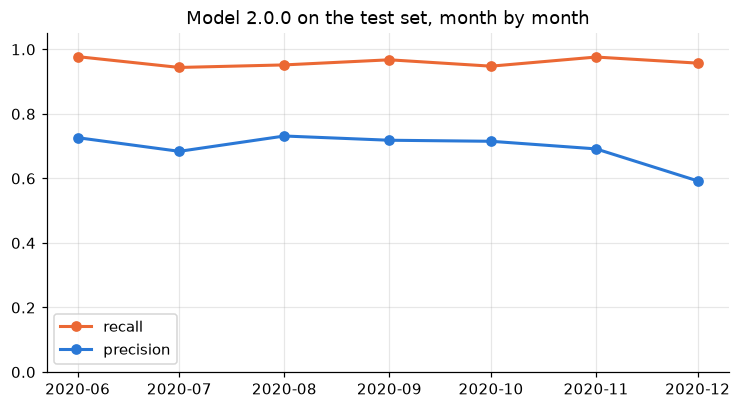

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
months = monthly.index.to_timestamp()
ax.plot(months, monthly["recall"], lw=2, marker="o", color=FRAUD, label="recall")
ax.plot(months, monthly["precision"], lw=2, marker="o", color=LEGIT, label="precision")
ax.set_ylim(0, 1.05)
ax.set_title("Model 2.0.0 on the test set, month by month")
ax.legend()
fig.savefig(FIGURES / "test_monthly.png", bbox_inches="tight")

## Conclusions

- **Model 2.0.0 holds up.** Its PR-AUC is 0.959 on test against 0.973 on cv. The small drop is the expected optimism of having tuned everything on cv, and it stays far ahead of model 1.0.0, which scores 0.833 on test.
- **At its released threshold,** model 2.0.0 catches 95.8% of the test frauds with a precision of 69%: it misses 90 of 2,145 frauds and raises 906 false alarms. That costs \$32,608 against \$1.13 million with no model, 97% less. The test period has 50% more transactions than cv and a lower fraud rate, so its totals are not directly comparable with cv's.
- **Month by month,** recall stays between 94% and 98%. Precision holds around 0.7 until November and falls to 0.59 in December, when purchase volume nearly doubles and the fraud rate drops to 0.19%: with many more legit purchases at the same threshold, false alarms grow relative to frauds. This is drift in the base rate. In production, monitoring the share of flagged purchases would catch it, and the threshold would be revisited on fresh data, not on this test set.
- **These are the final numbers.** No model changes are made because of them; doing so would turn the test set into a second cv set and leave the project without an honest estimate.